In [22]:
from src.parametric_estimation import ParametricEstimation
from src.missing_data_generator import MissingDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import logistic
from sklearn.metrics import root_mean_squared_error
from joblib import Parallel, delayed

In [23]:
n = 2000
d = 20
n_pat = 5
k_range = (0,20)
eps = 1e-2
fast = True # only Xtrain
var_index = 0
p = 0.1

In [24]:
# Specify data model
mdg = MissingDataGenerator(n=n, d=d, n_pat=n_pat, seed=1, distr='logistic') # the patterns is sampled once in the init

In [25]:
# Single job
def job(
        # n:int = None, # sample size
        # d:int = None, # data dimension
        # patterns = None, # arg of mice:ampute
        # prop:float = None, # arg of mice::ampute
        eps: float = None, # clamping scale
        fast: bool = None, # if fast, use fast algorithm of nmm
        var_index:int = None, # which variable
        p:float = None, # quantile
        ):
    X = mdg.get_X()
    _, M = mdg.ampute(X)
    pe = ParametricEstimation(X=X, M=M)
    ps_gmm = pe._propensity_score_Xc(method='gmm', eps=eps)
    ps_nmm = pe._propensity_score_Xc(method='nmm', eps=eps, fast=fast)
    qs = (
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_gmm).item(), 
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_nmm).item(),
        pe.quantile_by_generation(var_index=var_index, p=p).item(),
    )
    ms = np.stack(
        [
            pe.mean_by_ipw(propensity_score=ps_gmm), 
            pe.mean_by_ipw(propensity_score=ps_nmm),
            pe.mean_by_generation(),
        ],
        axis=0
    )
    return qs, ms

In [26]:
B = 50 # CHANGE

results = Parallel(n_jobs=15)(
    delayed(job)(
        eps=eps,
        fast=fast,
        var_index=var_index,
        p=p,
    )
    for _ in range(B)
)

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C"

Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast method only supports Xtrain
Fast metho

In [28]:
quantile_results = np.stack([q for q, _ in results])

mean_results = np.stack([
    np.sqrt(np.mean(np.square(m), axis=-1))
    for _, m in results
])

results = (quantile_results, mean_results)

# np.save('results/quantile_results.npy', quantile_results)
# np.save('results/mean_results.npy', mean_results)

ValueError: too many values to unpack (expected 2)

In [34]:
results

(array([[-2.26468179, -2.50814196, -2.24425793],
        [-1.66355638, -3.24089904, -2.43681884],
        [-2.19996171, -2.68114881, -2.28212547],
        [-2.85284686, -2.63841975, -2.43398237],
        [-2.18239247, -2.58450482, -2.28510928],
        [-2.52600024, -2.19552576, -2.43147635],
        [-2.97270124, -2.48316596, -2.3183279 ],
        [-2.10133638, -2.52263268, -2.27278662],
        [-2.53116624, -2.6572668 , -2.29618001],
        [-2.19704859, -2.11078202, -2.30080104],
        [-2.55381192, -2.81909509, -2.38633347],
        [-2.76661445, -2.75909092, -2.41776752],
        [-1.95676884, -2.81876509, -2.21602273],
        [-2.22661711, -2.52090499, -2.37670088],
        [-2.7094355 , -2.91855074, -2.19150424],
        [-1.7199972 , -2.59640903, -2.32253075],
        [-3.34388   , -2.50775287, -2.22875977],
        [-3.12566124, -1.48400559, -2.31629944],
        [-2.45910419, -2.28282467, -2.29876709],
        [-2.10646522, -2.61835818, -2.33781433],
        [-2.20446767

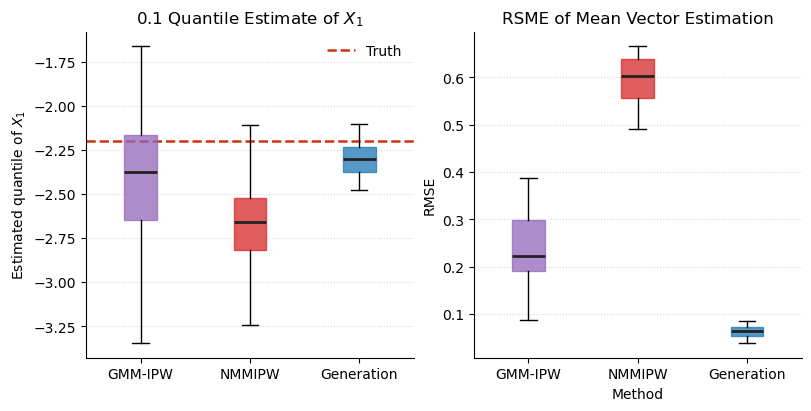

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

for ax, result in zip(axes, results):

    bp = ax.boxplot(
        result,
        tick_labels=['GMM-IPW', 'NMMIPW', 'Generation'],
        patch_artist=True,
        widths=0.3,
        # showmeans=True,
        showfliers=False,
        # meanprops=dict(
        #     marker="D",
        #     markerfacecolor="white",
        #     markeredgecolor="#333333",
        #     markersize=5,
        # ),
        medianprops=dict(color="#222222", linewidth=2),
        # whiskerprops=dict(color="#555555", linewidth=1.2),
        # capprops=dict(color="#555555", linewidth=1.2),
        # flierprops=dict(
        #     marker="o",
        #     markersize=4,
        #     markerfacecolor="#999999",
        #     markeredgecolor="none",
        #     alpha=0.6,
        # ),
    )

    # Colorblind-friendly palette
    colors = ["tab:purple", "tab:red", "tab:blue"]
    # colors = [sns.color_palette()[4], sns.color_palette()[3], "blue"]
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.75)
        box.set_edgecolor(color)

    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Reference quantile
y_ref = logistic.ppf(p)
axes[0].axhline(
    y=y_ref,
    color="#CC3311",
    linestyle="--",
    linewidth=1.8,
    label="Truth",
    zorder=0,
)

axes[0].set(
    title=fr"{p} Quantile Estimate of $X_1$",
    # xlabel="Method",
    ylabel=r"Estimated quantile of $X_1$",
)

axes[1].set(
    title=fr"RSME of Mean Vector Estimation",
    xlabel="Method",
    ylabel=r"RMSE",
)

axes[0].legend(frameon=False, loc="best")

plt.savefig(f'results/pe_quantile_mean_{n_pat}_patterns_{B}_B.png',dpi=300,
    bbox_inches="tight",)

plt.show()


In [8]:
results

(array([[-2.22015869, -1.60120391, -2.27375698],
        [-2.08196152, -1.87456468, -2.34865618],
        [-1.80538954, -1.84652387, -2.24926829],
        [-2.27370036, -1.94030085, -2.33290219],
        [-2.1481476 , -1.15469403, -2.55946374],
        [-2.31560646, -1.31710024, -2.3746531 ],
        [-2.0369918 , -1.49906087, -2.35008645],
        [-1.87732162, -1.60651525, -2.44633508],
        [-2.99662612, -1.89581383, -2.45725584],
        [-1.92650126, -1.34169471, -2.08262682],
        [-2.67063145, -1.83348329, -2.27598882],
        [-2.05114081, -1.47111946, -2.44477797],
        [-2.72290762, -1.67685502, -2.42384744],
        [-2.40984975, -1.86027691, -2.45139503],
        [-2.72855225, -1.64701064, -2.39697981],
        [-1.94621118, -1.70148988, -2.32903147],
        [-2.54744867, -2.22740272, -2.16847229],
        [-3.28145416, -1.70075773, -2.5018158 ],
        [-2.02191774, -1.99514837, -2.40464377],
        [-2.98994522, -1.82708655, -2.37579632],
        [-2.28332827